# Customer Lifetime Value & Segmentation Engine

## Project Overview

This project aims to develop a data-driven customer analytics system using the Online Retail II dataset.

The main objectives are:

- Analyze customer purchasing behavior.
- Segment customers based on their purchasing patterns using RFM analysis and K-Means clustering.
- Predict Customer Lifetime Value (CLV) by estimating customer spending over the next 90 days.
- Generate actionable business insights to support customer relationship management and marketing decisions.

The project follows a structured data science workflow, starting with data exploration and preprocessing, followed by feature engineering, customer segmentation, and predictive modeling.

## Problem Framing

**Who has the problem?** The marketing team of an online gift retailer. Today every customer receives the same treatment, so the budget is spent without knowing who is valuable.

**Decision supported:** who to reward, who to win back, and where to spend the marketing budget for the next quarter.

**Target variable:** `next_90d_spend`, the customer's net spending (sales minus returns) in the 90 days after a cutoff date. Customers who do not buy in this period have a target of 0.

**Two tasks:**
1. *Segmentation (unsupervised):* group customers by behavior using RFM features and K-Means. Quality is measured with the silhouette score and by how interpretable the segments are for marketing.
2. *Spend prediction (regression):* predict `next_90d_spend`.

**Business metric: MAE (Mean Absolute Error), in £.** It tells the marketing manager the average error per customer in money, which is easy to understand. We also report RMSE, because large wholesale customers matter more for revenue and RMSE penalizes big mistakes, and R² to compare with the baseline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "online_retail_II.xlsx"

xls = pd.ExcelFile(file_path)

print(xls.sheet_names)

['Year 2009-2010', 'Year 2010-2011']


# 1. Data Loading

In this stage, we load the Online Retail II dataset into the working environment.

The dataset contains two separate sheets representing different periods of retail transactions. Both sheets will be loaded and combined into a single DataFrame to provide a unified view of the available transaction history.

In [2]:
sheet_1= pd.read_excel(file_path, sheet_name=0)
sheet_2 = pd.read_excel(file_path, sheet_name=1)

In [3]:
sheet_1.shape


(525461, 8)

In [4]:
sheet_2.shape

(541910, 8)

### Combining Dataset Sheets

The two sheets are combined into one DataFrame to create a unified dataset containing all available transactions.

The original row indices are reset to ensure a consistent indexing structure after concatenation.

In [5]:
df = pd.concat([sheet_1, sheet_2], ignore_index=True)
print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


# 2. Data Understanding & Initial Inspection

In this stage, we explore the dataset to understand its structure, quality, and underlying patterns before applying any data cleaning operations.

The analysis focuses on:

- Understanding the dataset dimensions and data types.
- Identifying missing values.
- Investigating duplicate records.
- Exploring numerical distributions and statistical summaries.
- Examining unusual transaction values, including negative quantities and prices.

The findings from this stage will guide the data cleaning and preprocessing decisions.

### Data Source and Column Dictionary

**Source:** [Online Retail II, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/502)
**Content:** real transactions of a UK-based online gift retailer (many customers are wholesalers).
**Size:** 1,067,371 rows × 8 columns, from 2009-12-01 to 2011-12-09, in two Excel sheets.
**Class balance:** not applicable (the main task is regression). The target distribution is analyzed later.

| Column | Type | Meaning | Missing |
|---|---|---|---|
| Invoice | object | Invoice number. Starts with `C` for a cancellation | 0 |
| StockCode | object | Product code | 0 |
| Description | object | Product name | 4,382 |
| Quantity | int | Units purchased (negative = return/cancellation) | 0 |
| InvoiceDate | datetime | Date and time of the transaction | 0 |
| Price | float | Unit price (£) | 0 |
| Customer ID | float | Customer identifier | 243,007 (22.8%) |
| Country | object | Customer's country | 0 |
| TotalPrice | float | **Created by us:** `Quantity × Price` | 0 |

Each row is one **product line inside an invoice**, not a customer and not a full invoice.

In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [7]:
df.isnull().sum()


Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(34335)

In [9]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [10]:
df["Invoice"].astype(str).str.startswith("C").sum()

np.int64(19494)

In [11]:
df['TotalPrice'] = df['Quantity'] * df['Price']

In [12]:
df[['Quantity', 'Price', 'TotalPrice']].describe()

,Quantity,Price,TotalPrice
count,1.067371e+06,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00,1.806987e+01
std,1.727058e+02,1.235531e+02,2.924202e+02
min,-8.099500e+04,-5.359436e+04,-1.684696e+05
25%,1.000000e+00,1.250000e+00,3.750000e+00
50%,3.000000e+00,2.100000e+00,9.900000e+00
75%,1.000000e+01,4.150000e+00,1.770000e+01
max,8.099500e+04,3.897000e+04,1.684696e+05


In [13]:
df[df['Quantity'] < 0][['Invoice', 'Quantity', 'Price', 'TotalPrice']].head(10)

,Invoice,Quantity,Price,TotalPrice
178,C489449,-12,2.95,-35.40
179,C489449,-6,1.65,-9.90
180,C489449,-4,4.25,-17.00
181,C489449,-6,2.10,-12.60
182,C489449,-12,2.95,-35.40
183,C489449,-12,1.25,-15.00
184,C489449,-12,1.25,-15.00
185,C489449,-24,0.85,-20.40
186,C489449,-12,2.95,-35.40
196,C489459,-3,4.25,-12.75


In [14]:
df[df['Price'] < 0][['Invoice', 'StockCode', 'Description', 'Customer ID', 'Country']]

,Invoice,StockCode,Description,Customer ID,Country
179403,A506401,B,Adjust bad debt,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,NaN,United Kingdom


In [15]:
df[df['Description'].str.contains('bad debt', case=False, na=False)]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,-53594.36
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,-44031.79
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,-38925.87
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,11062.06
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,-11062.06
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,-11062.06


In [16]:
df[
    (df["Quantity"]<0) & (~df['Invoice'].str.startswith('C',na=False))
][['Invoice', 'Description', 'Quantity', 'Price', 'Customer ID']].head(10)

,Invoice,Description,Quantity,Price,Customer ID
263,489464,85123a mixed,-96,0.0,NaN
283,489463,short,-240,0.0,NaN
284,489467,21733 mixed,-192,0.0,NaN
470,489521,NaN,-50,0.0,NaN
3114,489655,NaN,-44,0.0,NaN
3162,489660,lost,-1043,0.0,NaN
3168,489663,damages,-117,0.0,NaN
4296,489806,NaN,-770,0.0,NaN
4538,489820,invcd as 84879?,-720,0.0,NaN
4566,489821,NaN,-240,0.0,NaN


In [17]:
duplicates = df[df.duplicated(keep=False)]
duplicates.head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom,7.80
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,5.10
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,1.95
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,5.10
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom,7.80
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75


# 3. Data Cleaning & Preprocessing

In this stage, we clean and preprocess the dataset based on the findings from the exploratory data analysis.

The goal is to prepare a reliable dataset for customer-level analysis while preserving valid transactions and avoiding unnecessary data loss.

In [18]:
df_clean = df.copy()

In [19]:
df_clean = df_clean.dropna(subset=['Customer ID'])

In [20]:
df_clean['Customer ID'].isna().sum()

np.int64(0)

In [21]:
df_clean.shape

(824364, 9)

In [22]:
df_clean["Description"].isna().sum()

np.int64(0)

In [23]:
(df_clean['Price'] < 0).sum()

np.int64(0)

In [24]:
(df_clean['Quantity'] < 0).sum()

np.int64(18744)

In [25]:
negative_quantity = df_clean[df_clean['Quantity'] < 0]

negative_quantity['Invoice'].str.startswith('C').value_counts()

Invoice
True    18744
Name: count, dtype: int64

In [26]:
(df_clean['Price']==0).sum()

np.int64(71)

In [27]:
df_clean.loc[
    df_clean['Price'] == 0
].sort_values('Quantity', ascending=False).head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.0,13256.0,United Kingdom,0.0
358820,524181,46000M,POLYESTER FILLER PAD 45x45cm,648,2010-09-27 16:59:00,0.0,17450.0,United Kingdom,0.0
823515,562973,23157,SET OF 6 NATIVITY MAGNETS,240,2011-08-11 11:42:00,0.0,14911.0,EIRE,0.0
961889,574138,23234,BISCUIT TIN VINTAGE CHRISTMAS,216,2011-11-03 11:26:00,0.0,12415.0,Australia,0.0
840207,564651,23268,SET OF 2 CERAMIC CHRISTMAS REINDEER,192,2011-08-26 14:19:00,0.0,14646.0,Netherlands,0.0
840209,564651,21786,POLKADOT RAIN HAT,144,2011-08-26 14:19:00,0.0,14646.0,Netherlands,0.0
840208,564651,22955,36 FOIL STAR CAKE CASES,144,2011-08-26 14:19:00,0.0,14646.0,Netherlands,0.0
840206,564651,23270,SET OF 2 CERAMIC PAINTED HEARTS,96,2011-08-26 14:19:00,0.0,14646.0,Netherlands,0.0
723844,554037,22619,SET OF 6 SOLDIER SKITTLES,80,2011-05-20 14:13:00,0.0,12415.0,Australia,0.0
392008,527084,22630,DOLLY GIRL LUNCH BOX,64,2010-10-14 15:33:00,0.0,14646.0,Netherlands,0.0


In [28]:
zero_price_invoices = df_clean.groupby('Invoice').agg(
    has_zero_price=('Price', lambda x: (x == 0).any()),
    has_paid_items=('Price', lambda x: (x > 0).any())
)

zero_price_invoices[
    zero_price_invoices['has_zero_price']
].value_counts()

has_zero_price  has_paid_items
True            True              55
                False              6
Name: count, dtype: int64

In [29]:
zero_only_invoices = zero_price_invoices[
    zero_price_invoices['has_zero_price'] &
    ~zero_price_invoices['has_paid_items']
].index

df_clean[df_clean['Invoice'].isin(zero_only_invoices)][
    ['Invoice', 'StockCode', 'Description', 'Quantity',
     'Price', 'Customer ID', 'Country']
]

,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country
89084,497819,TEST001,This is a test product.,5,0.0,14103.0,United Kingdom
89180,497843,TEST001,This is a test product.,5,0.0,14827.0,United Kingdom
612250,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,0.0,17560.0,United Kingdom
840206,564651,23270,SET OF 2 CERAMIC PAINTED HEARTS,96,0.0,14646.0,Netherlands
840207,564651,23268,SET OF 2 CERAMIC CHRISTMAS REINDEER,192,0.0,14646.0,Netherlands
840208,564651,22955,36 FOIL STAR CAKE CASES,144,0.0,14646.0,Netherlands
840209,564651,21786,POLKADOT RAIN HAT,144,0.0,14646.0,Netherlands
887286,568384,M,Manual,1,0.0,12748.0,United Kingdom
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.0,13256.0,United Kingdom


In [30]:
df_clean['Quantity'].describe(
    percentiles=[0.90, 0.95, 0.99, 0.999]
)

count    824364.000000
mean         12.414574
std         188.976099
min      -80995.000000
50%           5.000000
90%          24.000000
95%          36.000000
99%         120.000000
99.9%       576.000000
max       80995.000000
Name: Quantity, dtype: float64

In [31]:
df_clean[df_clean['Quantity'] > 0].nlargest(
    10, 'Quantity'
)[
    ['Invoice', 'StockCode', 'Description',
     'Quantity', 'Price', 'Customer ID', 'Country']
]

,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,United Kingdom
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,United Kingdom
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902.0,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902.0,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902.0,Denmark
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902.0,Denmark
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,13256.0,United Kingdom
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,13902.0,Denmark
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,17940.0,United Kingdom
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,17940.0,United Kingdom


### Fixing Data Types
The `Invoice` column mixes integers and strings (e.g. `581483` and `C489449`).
We convert it to string so filtering works correctly. `Customer ID` is converted to integer because IDs are whole numbers.

In [32]:
df_clean['Invoice'] = df_clean['Invoice'].astype(str)
df_clean['Customer ID'] = df_clean['Customer ID'].astype(int)

print(df_clean['Invoice'].map(type).value_counts())
df_clean[df_clean['Invoice'].isin(['581483', '541431'])][
    ['Invoice', 'Description', 'Quantity', 'Price', 'Customer ID', 'InvoiceDate']
]

Invoice
<class 'str'>    824364
Name: count, dtype: int64


,Invoice,Description,Quantity,Price,Customer ID,InvoiceDate
587080,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346,2011-01-18 10:01:00
1065882,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446,2011-12-09 09:15:00


### Checking the Largest Orders
The two largest orders (invoices `541431` and `581483`) look like huge wholesale purchases.
We check whether a cancellation invoice (starting with `C`) exists for each of them.

In [33]:
big_orders = df_clean[df_clean['Invoice'].isin(['541431', 'C541433', '581483', 'C581484'])]

big_orders[['Invoice', 'Description', 'Quantity', 'TotalPrice', 'Customer ID', 'InvoiceDate']]

,Invoice,Description,Quantity,TotalPrice,Customer ID,InvoiceDate
587080,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,77183.6,12346,2011-01-18 10:01:00
587085,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,-77183.6,12346,2011-01-18 10:17:00
1065882,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.6,16446,2011-12-09 09:15:00
1065883,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,-168469.6,16446,2011-12-09 09:27:00


**Finding:** both orders were fully cancelled a few minutes later (`C541433` and `C581484`), so their net value is zero.
This confirms our decision to keep returns and cancellations: they are needed to measure each customer's *net* spending.

In [34]:
df_clean['StockCode'] = df_clean['StockCode'].astype(str)

df_clean[~df_clean['StockCode'].str.match(r'^\d{5}')]['StockCode'].value_counts()

StockCode
POST            2019
M               1115
C2               259
D                174
ADJUST            61
BANK CHARGES      38
PADS              19
DOT               16
CRUK              16
TEST001           15
ADJUST2            3
SP1002             2
TEST002            1
Name: count, dtype: int64

In [35]:
codes_to_remove = ['POST', 'M', 'C2', 'D', 'ADJUST', 'ADJUST2', 'BANK CHARGES',
                   'PADS', 'DOT', 'CRUK', 'TEST001', 'TEST002']

df_clean[df_clean['StockCode'].isin(codes_to_remove)].groupby('StockCode')['Description'].first()

StockCode
ADJUST          Adjustment by john on 26/01/2010 16
ADJUST2         Adjustment by Peter on Jun 25 2010 
BANK CHARGES                           Bank Charges
C2                                         CARRIAGE
CRUK                                CRUK Commission
D                                          Discount
DOT                                  DOTCOM POSTAGE
M                                            Manual
PADS                     PADS TO MATCH ALL CUSHIONS
POST                                        POSTAGE
TEST001                     This is a test product.
TEST002                     This is a test product.
Name: Description, dtype: object

### Removing Non-Product Records
Some `StockCode` values do not represent real products: postage, manual entries, discounts, bank charges, adjustments, and test records.
These rows describe accounting operations, not customer purchasing behavior, so we remove them.
We also remove rows with `Price = 0`, because they add no revenue and invoices made only of free items would inflate purchase frequency.
We keep returns (negative quantities) because we measure each customer's *net* spending.

In [36]:
rows_before = len(df_clean)

# 1) Remove non-product codes
df_clean = df_clean[~df_clean['StockCode'].isin(codes_to_remove)]

# 2) Remove zero-price rows
df_clean = df_clean[df_clean['Price'] > 0]

print(f"Rows before: {rows_before:,}")
print(f"Rows after : {len(df_clean):,}")
print(f"Removed    : {rows_before - len(df_clean):,}")

Rows before: 824,364
Rows after : 820,567
Removed    : 3,797


In [37]:
print((df_clean['Price'] <= 0).sum())                                  # expect 0
print(df_clean['StockCode'].isin(codes_to_remove).sum())               # expect 0
print(df_clean['Invoice'].str.startswith('C').sum())                   # returns still there
print(df_clean['Customer ID'].nunique())                               # number of customers
print(df_clean['InvoiceDate'].min(), df_clean['InvoiceDate'].max())

0
0
17933
5875
2009-12-01 07:45:00 2011-12-09 12:50:00


### Cleaning Summary
- Removed rows without `Customer ID` (about 23% of rows; they cannot be assigned to a customer).
- Removed non-product records (postage, discounts, manual entries, bank charges, adjustments, tests) and zero-price rows.
- Kept returns/cancellations to calculate each customer's **net** spending (e.g. invoice 581483 for £168K was fully cancelled by C581484).
- Kept exact duplicate rows (26,402): identical rows can be legitimate repeated scans of the same item in one invoice.
- Kept large orders: they are real wholesale purchases, not errors.
- Result: 820,567 rows from 5,875 customers.

In [38]:
df_clean = df_clean.reset_index(drop=True)

print("Duplicates:", df_clean.duplicated().sum())

df_clean.to_pickle("online_retail_clean.pkl")

Duplicates: 26402


# 4. Exploratory Data Analysis (EDA)

After cleaning, we explore the transactions visually to understand sales patterns over time, by country, and by invoice value.
Customer-level analysis (RFM distributions and correlations) is added after the RFM features are built.

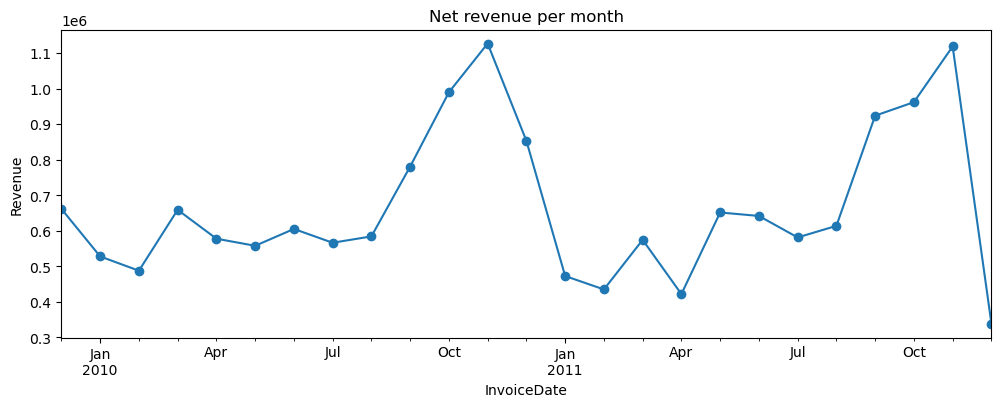

1. **Seasonality:** revenue rises from August and peaks in November in both years, then drops sharply in January. The last point (December 2011) is low only because the data ends on 9 December.


In [ ]:
# 1) Net revenue per month
monthly = df_clean.groupby(df_clean['InvoiceDate'].dt.to_period('M'))['TotalPrice'].sum()
monthly.plot(kind='line', marker='o', figsize=(12, 4), title='Net revenue per month')
plt.ylabel('Revenue')
plt.show()

### Insight 1 
 **Seasonality**: revenue rises from August and peaks in November in both years, then drops sharply in January. The last point (December 2011) is low only because the data ends on 9 December.

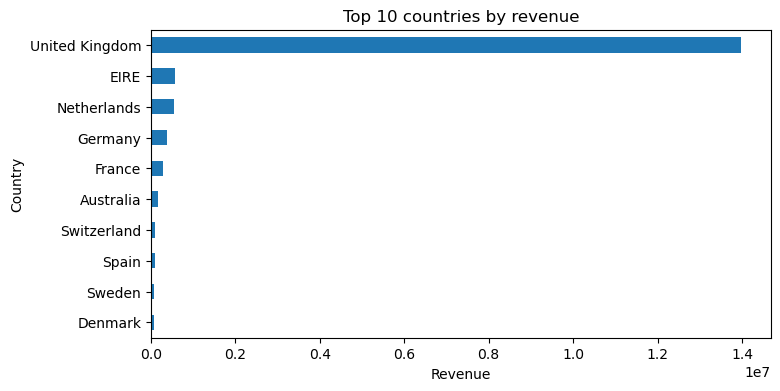

In [40]:
# 2) Top 10 countries by revenue
(df_clean.groupby('Country')['TotalPrice'].sum()
         .sort_values().tail(10)
         .plot(kind='barh', figsize=(8, 4), title='Top 10 countries by revenue'))
plt.xlabel('Revenue')
plt.show()

### Insight 2 
**Geography** : the United Kingdom dominates revenue by a very large margin.

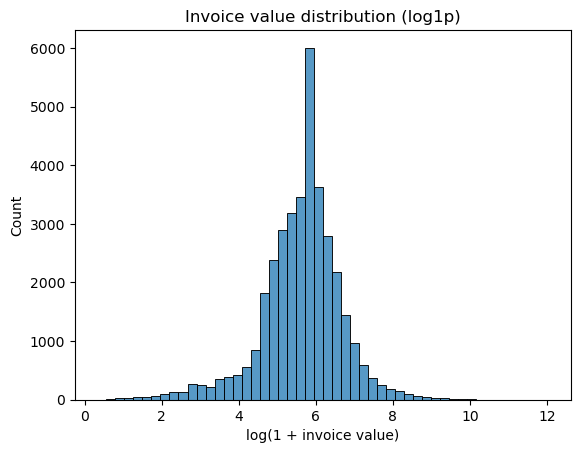

In [41]:
# 3) Distribution of invoice value (sales only, log scale)
sales = df_clean[~df_clean['Invoice'].str.startswith('C')]
invoice_value = sales.groupby('Invoice')['TotalPrice'].sum()

sns.histplot(np.log1p(invoice_value), bins=50)
plt.title('Invoice value distribution (log1p)')
plt.xlabel('log(1 + invoice value)')
plt.show()

### Insight 3
 **Invoice value:** after a log transform the distribution is close to normal, with a long right tail of wholesale orders. We will apply a log transform before clustering.

# 5. Feature Engineering (RFM)

In [42]:
cutoff_date = pd.Timestamp('2011-09-11')
target_end  = cutoff_date + pd.Timedelta(days=90)   # 2011-12-10 (exclusive)

obs    = df_clean[df_clean['InvoiceDate'] < cutoff_date]
future = df_clean[(df_clean['InvoiceDate'] >= cutoff_date) &
                  (df_clean['InvoiceDate'] < target_end)]

sales_obs = obs[~obs['Invoice'].str.startswith('C')]

rfm = sales_obs.groupby('Customer ID').agg(
    last_purchase=('InvoiceDate', 'max'),
    Frequency=('Invoice', 'nunique')
)
rfm['Recency']  = (cutoff_date - rfm['last_purchase']).dt.days
rfm['Monetary'] = obs.groupby('Customer ID')['TotalPrice'].sum()
rfm = rfm.drop(columns='last_purchase')

print(rfm.shape)
print(rfm.describe())
print("Customers with Monetary <= 0:", (rfm['Monetary'] <= 0).sum())

(5256, 3)
         Frequency      Recency       Monetary
count  5256.000000  5256.000000    5256.000000
mean      5.711377   206.887747    2584.299462
std      11.213991   174.372666   12117.138032
min       1.000000     1.000000   -1663.060000
25%       1.000000    50.000000     314.722500
50%       3.000000   164.000000     783.840000
75%       6.000000   325.000000    2053.257500
max     284.000000   648.000000  482036.700000
Customers with Monetary <= 0: 11


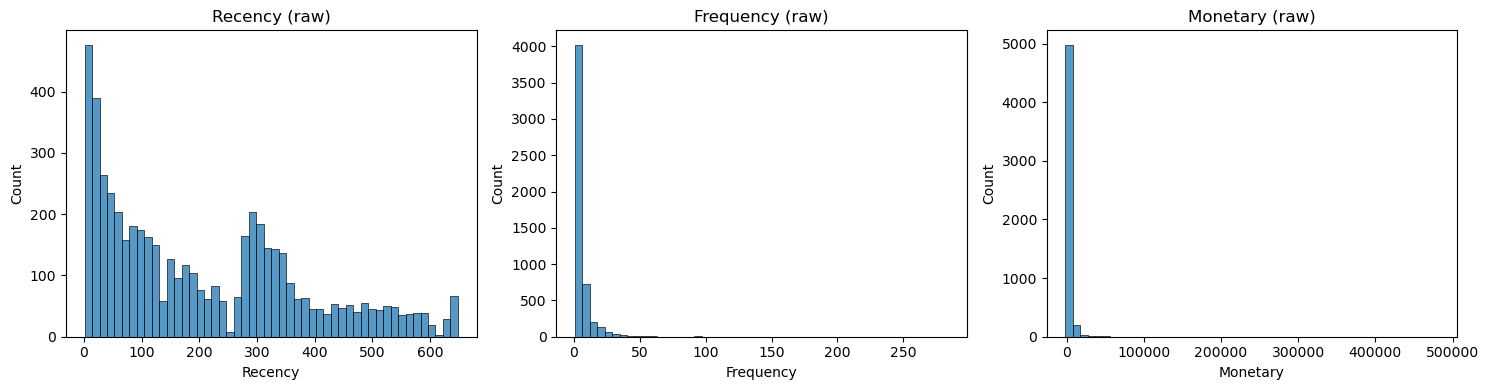

In [43]:
# Univariate: distributions of R, F, M (raw)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    sns.histplot(rfm[col], bins=50, ax=ax)
    ax.set_title(f'{col} (raw)')
plt.tight_layout()
plt.show()

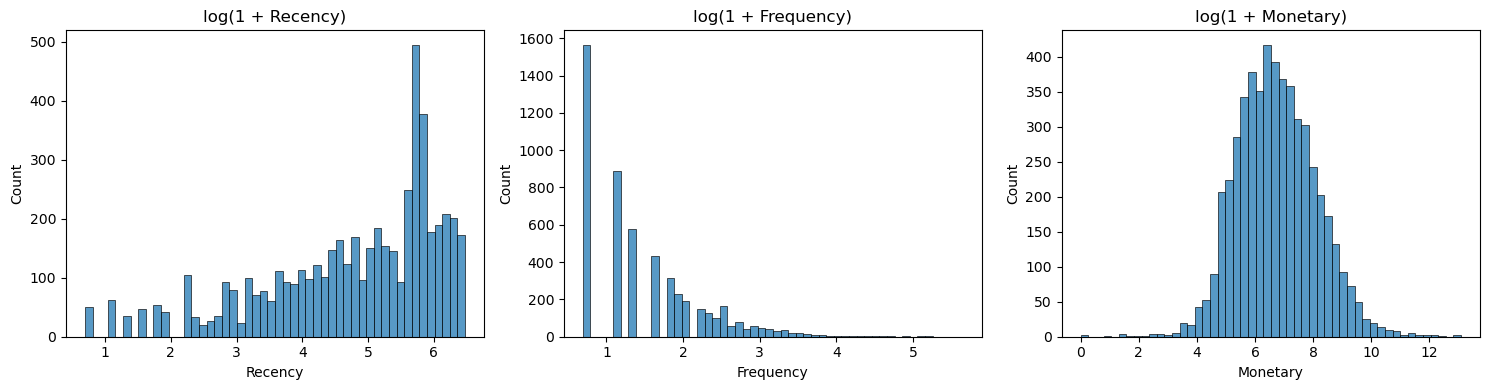

In [44]:
# Univariate after log transform (only customers with positive spending)
rfm_pos = rfm[rfm['Monetary'] > 0]
rfm_log = np.log1p(rfm_pos[['Recency', 'Frequency', 'Monetary']])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, rfm_log.columns):
    sns.histplot(rfm_log[col], bins=50, ax=ax)
    ax.set_title(f'log(1 + {col})')
plt.tight_layout()
plt.show()

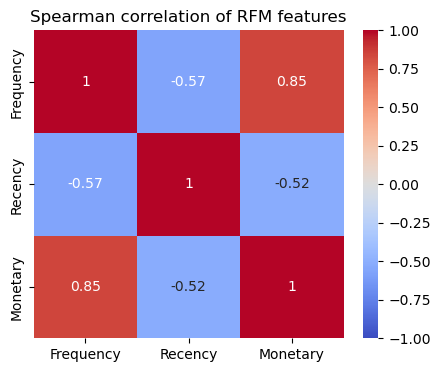

In [45]:
# Multivariate: correlation heatmap (Spearman is robust to skewed data)
plt.figure(figsize=(5, 4))
sns.heatmap(rfm.corr(method='spearman'), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Spearman correlation of RFM features')
plt.show()

# 6. Target Creation (Next 90-Day Spend)

For each customer in the observation window, the target is the **net spending in the 90 days after the cutoff date**.
Customers who did not buy in that period get a target of 0 (they are real examples of customers who churned or paused).
Customers who appear for the first time after the cutoff are excluded, because we have no history to predict from.

In [47]:
target = (future.groupby('Customer ID')['TotalPrice'].sum().rename('next_90d_spend'))

customers = rfm.join(target, how='left')
customers['next_90d_spend'] = customers['next_90d_spend'].fillna(0)

print("Shape:", customers.shape)
print("Share of customers with zero spend:", (customers['next_90d_spend'] == 0).mean().round(3))
print("Customers with negative target:", (customers['next_90d_spend'] < 0).sum())
print(customers['next_90d_spend'].describe())

Shape: (5256, 4)
Share of customers with zero spend: 0.559
Customers with negative target: 34
count      5256.000000
mean        523.474425
std        3171.976927
min        -468.320000
25%           0.000000
50%           0.000000
75%         426.165000
max      124206.550000
Name: next_90d_spend, dtype: float64


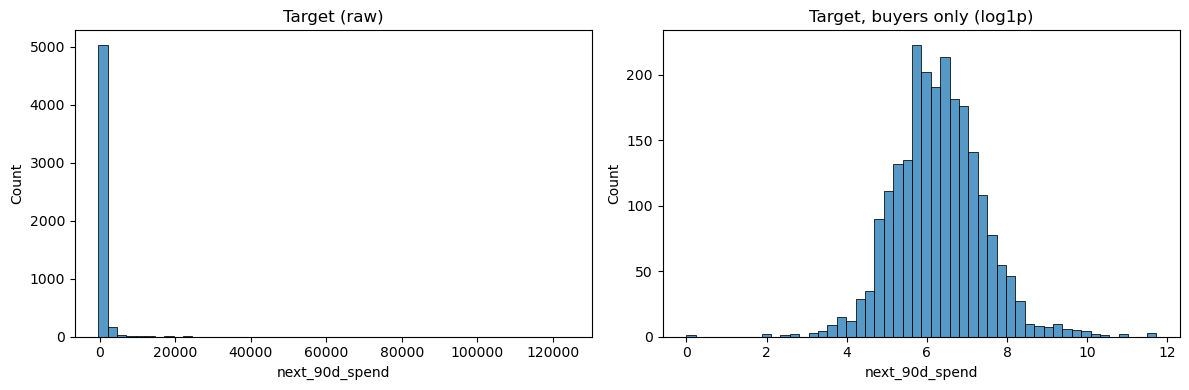

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(customers['next_90d_spend'], bins=50, ax=axes[0])
axes[0].set_title('Target (raw)')

sns.histplot(np.log1p(customers.loc[customers['next_90d_spend'] > 0, 'next_90d_spend']),
             bins=50, ax=axes[1])
axes[1].set_title('Target, buyers only (log1p)')

plt.tight_layout()
plt.show()

In [49]:
# 1) Spending cannot be negative: returns of old purchases are not "spending"
customers['next_90d_spend'] = customers['next_90d_spend'].clip(lower=0)

# 2) How many customers have zero or negative net spending in the observation window?
print("Monetary <= 0:", (customers['Monetary'] <= 0).sum())

# 3) Who are the biggest spenders in the target window?
customers.sort_values('next_90d_spend', ascending=False).head(10)

Monetary <= 0: 11


,Frequency,Recency,Monetary,next_90d_spend
Customer ID,,,,
18102,112,8,482036.70,124206.55
17450,28,5,132558.76,103273.99
14646,115,2,421794.34,101408.40
14911,284,3,204105.99,58757.06
14096,3,1,203.89,53054.54
16684,45,43,108760.23,32770.06
17511,50,3,142793.66,29105.14
14088,10,38,38747.71,24983.92
12415,18,9,120454.37,22652.65


### Insights
1. **Zero-inflated target:** about 56% of customers didn't buy in the next 90 days, so a model must beat the "predict zero" baseline.
2. **Heavy right tail:** the top 10 customers generate about 21% of the revenue in the window. We train on `log1p(target)` so a few wholesale customers do not dominate the model.
3. **Hard cases:** some customers like "14096" have almost no history but spend a lot later. RFM cannot predict this, and we analyze such errors in the evaluation stage, this will be a limitation in the model

# 7. Train/Test Split

Spliting the data to avoid data leakage and as the pdf said **before fitting anything**
The test set is kept untouched until the final evaluation.
We stratify by "buyer / non-buyer" so both sets have the same share of zero-spend customers.

In [50]:
from sklearn.model_selection import train_test_split

# Remove customers whose returns exceeded their purchases
customers = customers[customers['Monetary'] > 0].copy()

X = customers[['Recency', 'Frequency', 'Monetary']]
y = customers['next_90d_spend']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=(y > 0)
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Zero-spend share  train:", (y_train == 0).mean().round(3),
      "| test:", (y_test == 0).mean().round(3))

Train: (4196, 3) | Test: (1049, 3)
Zero-spend share  train: 0.565 | test: 0.565


# 8. Customer Segmentation (K-Means)

K-Means groups customers by distance, so the RFM features must be on a similar scale.
We apply `log1p` (to reduce skewness) and `StandardScaler`, both **fitted on the training set only**.
We then compare k = 2 to 8 using the Elbow method (inertia) and the Silhouette score.

c:\Users\aemk5\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\aemk5\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\aemk5\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\aemk5\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

   k   inertia  silhouette
0  2  6163.994       0.458
1  3  4587.322       0.353
2  4  3605.451       0.377
3  5  3019.647       0.335
4  6  2667.535       0.328
5  7  2387.578       0.288
6  8  2177.874       0.287


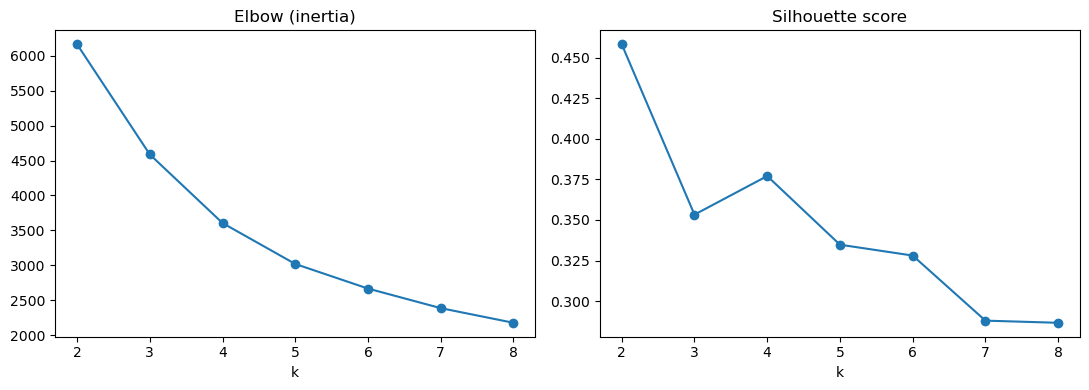

In [51]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

prep = Pipeline([
    ('log', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())
])
X_train_prep = prep.fit_transform(X_train)

results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_train_prep)
    results.append((k, km.inertia_, silhouette_score(X_train_prep, labels)))

res = pd.DataFrame(results, columns=['k', 'inertia', 'silhouette'])
print(res.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(res['k'], res['inertia'], marker='o')
axes[0].set_title('Elbow (inertia)')
axes[0].set_xlabel('k')
axes[1].plot(res['k'], res['silhouette'], marker='o')
axes[1].set_title('Silhouette score')
axes[1].set_xlabel('k')
plt.tight_layout()
plt.show()

### Choosing k
k = 2 has the highest silhouette score (0.458), but it only separates active from inactive customers, which is too coarse for marketing.
k = 4 is a local maximum of the silhouette score (0.377), the elbow flattens after it, and it gives a number of segments marketing can act on. We choose **k = 4**.

In [52]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

train_seg = X_train.copy()
train_seg['Segment'] = kmeans.fit_predict(X_train_prep)

profile = train_seg.groupby('Segment').agg(
    Customers=('Recency', 'size'),
    Recency=('Recency', 'median'),
    Frequency=('Frequency', 'median'),
    Monetary=('Monetary', 'median')
)
profile['Share_%'] = (profile['Customers'] / len(train_seg) * 100).round(1)

seg = train_seg['Segment']
profile['Buyers_next_90d_%'] = y_train.groupby(seg).apply(lambda s: (s > 0).mean() * 100).round(1)
profile['Avg_next_90d_spend'] = y_train.groupby(seg).mean().round(0)
profile['Revenue_share_%'] = (y_train.groupby(seg).sum() / y_train.sum() * 100).round(1)

profile

,Customers,Recency,Frequency,Monetary,Share_%,Buyers_next_90d_%,Avg_next_90d_spend,Revenue_share_%
Segment,,,,,,,,
0,545,26.0,3.0,623.160,13.0,54.9,414.0,10.2
1,1285,174.0,4.0,1408.960,30.6,46.4,332.0,19.2
2,718,23.0,13.0,5140.680,17.1,84.1,1994.0,64.5
3,1648,330.0,1.0,287.575,39.3,19.8,82.0,6.1


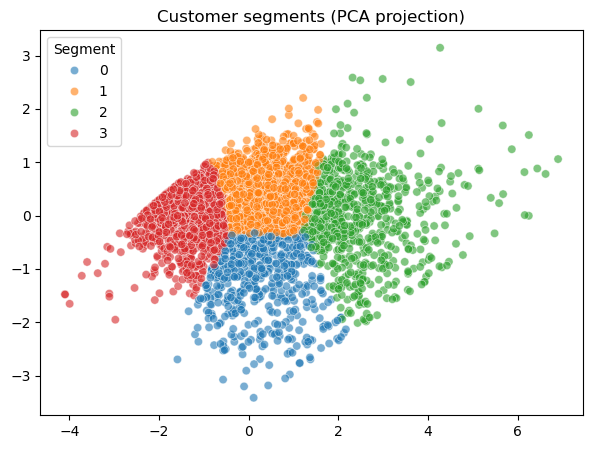

Explained variance: [0.759 0.189]


In [53]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_train_prep)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=train_seg['Segment'],
                palette='tab10', alpha=0.6)
plt.title('Customer segments (PCA projection)')
plt.show()

print("Explained variance:", pca.explained_variance_ratio_.round(3))

In [58]:
segment_names = {0: 'Future money pocket', 1: 'At Risk', 2: 'VIP', 3: 'Lost'}

actions = {
    'VIP':'Reward: loyalty program and early access to new products',
    'Future money pocket':'Grow: welcome offers and bundles to encourage repeat purchases',
    'At Risk':'Win back: reminder emails with a targeted discount',
    'Lost':'Low cost only: occasional newsletter, no discounts'
}

train_seg['Segment_Name'] = train_seg['Segment'].map(segment_names)

summary = (train_seg.assign(next_90d_spend=y_train)
           .groupby('Segment_Name')
           .agg(Customers=('Recency', 'size'),
                Revenue_at_stake=('next_90d_spend', 'sum')))

summary['Revenue_at_stake'] = summary['Revenue_at_stake'].round(0)
summary['Action'] = summary.index.map(actions)
summary.sort_values('Revenue_at_stake', ascending=False)

,Customers,Revenue_at_stake,Action
Segment_Name,,,
VIP,718,1432028.0,Reward: loyalty program and early access to ne...
At Risk,1285,427252.0,Win back: reminder emails with a targeted disc...
Future money pocket,545,225885.0,Grow: welcome offers and bundles to encourage ...
Lost,1648,135166.0,"Low cost only: occasional newsletter, no disco..."


### Hierarchical Clustering (comparison)
We compare K-Means with Agglomerative (Ward) clustering using the same 4 clusters and the same prepared training features.
We compare the silhouette scores and how much the two methods agree (Adjusted Rand Index).

In [59]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

hc = AgglomerativeClustering(n_clusters=4, linkage='ward')
hc_labels = hc.fit_predict(X_train_prep)

print("Silhouette - KMeans      :", round(silhouette_score(X_train_prep, train_seg['Segment']), 3))
print("Silhouette - Hierarchical:", round(silhouette_score(X_train_prep, hc_labels), 3))
print("Agreement (ARI):", round(adjusted_rand_score(train_seg['Segment'], hc_labels), 3))

pd.crosstab(train_seg['Segment_Name'], hc_labels)

Silhouette - KMeans      : 0.377
Silhouette - Hierarchical: 0.309
Agreement (ARI): 0.611


col_0,0,1,2,3
Segment_Name,,,,
At Risk,32,139,1114,0
Future money pocket,238,23,158,126
Lost,1512,0,136,0
VIP,0,574,7,137


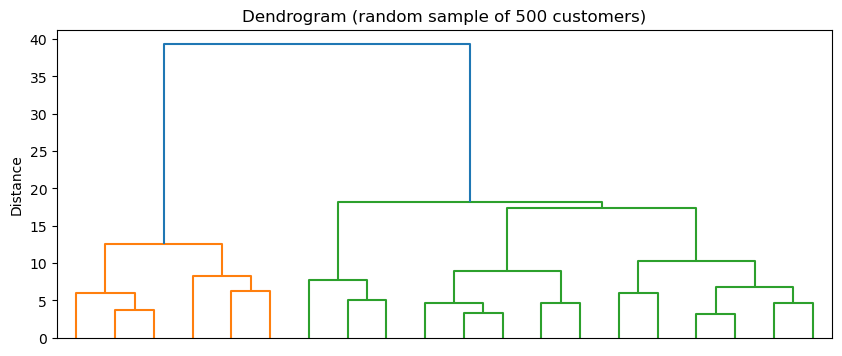

In [60]:
from scipy.cluster.hierarchy import linkage, dendrogram

sample_idx = np.random.RandomState(42).choice(len(X_train_prep), 500, replace=False)
Z = linkage(X_train_prep[sample_idx], method='ward')

plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode='lastp', p=20, no_labels=True)
plt.title('Dendrogram (random sample of 500 customers)')
plt.ylabel('Distance')
plt.show()

### Decision: K-Means
K-Means has a higher silhouette score (0.377 vs 0.309), and the two methods agree reasonably well (ARI = 0.61), which supports the stability of the segments.
Lost, At Risk and VIP are stable across both methods, while "Future money pocket" is the least stable segment (its customers sit on the boundaries).
We keep K-Means because it can assign a new customer to a segment with a single `predict` call, which the web app needs.
The dendrogram shows two main branches (the largest jump is at distance ~39), so k = 4 is a finer split that is acceptable but not sharply supported.

# 9. CLV Prediction (Regression)

We predict `next_90d_spend` from the RFM features.
We first set simple baselines, then compare three algorithms (Ridge, Random Forest, Gradient Boosting) using 5-fold cross-validation on the **training set only**.
The test set stays untouched until the final evaluation.
Because the target is heavily skewed, the models are trained on `log1p(target)` and their predictions are converted back to pounds before computing the metrics.

In [61]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_validate, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def make_model(estimator, scale=False):
    steps = [('log', FunctionTransformer(np.log1p))]
    if scale:
        steps.append(('scale', StandardScaler()))
    steps.append(('model', estimator))
    return TransformedTargetRegressor(
        regressor=Pipeline(steps),
        func=np.log1p,
        inverse_func=np.expm1
    )

models = {
    'Baseline: mean': DummyRegressor(strategy='mean'),
    'Baseline: median (zero)': DummyRegressor(strategy='median'),
    'Ridge': make_model(Ridge(alpha=1.0), scale=True),
    'Random Forest': make_model(RandomForestRegressor(
        n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)),
    'Gradient Boosting': make_model(GradientBoostingRegressor(random_state=42)),
}

rows = []
for name, model in models.items():
    cv = cross_validate(model, X_train, y_train, cv=kf,
                        scoring={'mae': 'neg_mean_absolute_error',
                                 'rmse': 'neg_root_mean_squared_error',
                                 'r2': 'r2'})
    rows.append({'Model': name,
                 'MAE': -cv['test_mae'].mean(),
                 'RMSE': -cv['test_rmse'].mean(),
                 'R2': cv['test_r2'].mean()})

cv_results = pd.DataFrame(rows).round(2).sort_values('MAE')
cv_results

,Model,MAE,RMSE,R2
3,Random Forest,411.19,2031.64,0.45
4,Gradient Boosting,422.26,2152.29,0.38
2,Ridge,432.22,2041.81,0.39
1,Baseline: median (zero),529.15,2719.30,-0.07
0,Baseline: mean,709.37,2664.91,-0.01


In [62]:
last90_start = cutoff_date - pd.Timedelta(days=90)

obs_sales = obs[~obs['Invoice'].str.startswith('C')]
obs_ret   = obs[obs['Invoice'].str.startswith('C')]
recent    = obs[obs['InvoiceDate'] >= last90_start]
recent_sales = recent[~recent['Invoice'].str.startswith('C')]

g = obs_sales.groupby('Customer ID')

extra = pd.DataFrame({
    'Tenure': (cutoff_date - g['InvoiceDate'].min()).dt.days,
    'UniqueProducts': g['StockCode'].nunique(),
    'GrossSales': g['TotalPrice'].sum()
})

extra['AvgOrderValue'] = extra['GrossSales'] / rfm['Frequency']

returns_value = (-obs_ret.groupby('Customer ID')['TotalPrice'].sum()).reindex(extra.index).fillna(0)
extra['ReturnShare'] = returns_value / extra['GrossSales']

extra['Spend_last90'] = (recent.groupby('Customer ID')['TotalPrice'].sum()
                         .reindex(extra.index).fillna(0).clip(lower=0))
extra['Orders_last90'] = (recent_sales.groupby('Customer ID')['Invoice'].nunique()
                          .reindex(extra.index).fillna(0))

extra = extra.drop(columns='GrossSales')

feat = rfm.join(extra)

# same customers in the same split as before
X_train2 = feat.loc[X_train.index]
X_test2  = feat.loc[X_test.index]

print(X_train2.shape, X_test2.shape)
print(X_train2.isna().sum().sum(), "missing values")
X_train2.describe().round(2)

(4196, 9) (1049, 9)
0 missing values


,Frequency,Recency,Monetary,Tenure,UniqueProducts,AvgOrderValue,ReturnShare,Spend_last90,Orders_last90
count,4196.00,4196.00,4196.00,4196.00,4196.00,4196.00,4196.00,4196.00,4196.00
mean,5.83,208.09,2667.46,434.35,75.38,383.35,0.02,339.44,0.75
std,11.89,174.35,13122.71,179.01,108.82,683.60,0.07,1957.83,1.86
min,1.00,1.00,0.00,1.00,1.00,1.55,0.00,0.00,0.00
25%,1.00,50.00,317.76,317.00,18.00,179.48,0.00,0.00,0.00
50%,3.00,166.00,792.66,478.00,41.00,283.95,0.00,0.00,0.00
75%,6.00,327.00,2087.20,587.00,92.00,421.45,0.01,250.80,1.00
max,284.00,648.00,482036.70,648.00,2178.00,25784.32,1.00,61791.70,45.00


In [63]:
def run_cv(X, y, models):
    rows = []
    for name, model in models.items():
        cv = cross_validate(model, X, y, cv=kf,
                            scoring={'mae': 'neg_mean_absolute_error',
                                     'rmse': 'neg_root_mean_squared_error',
                                     'r2': 'r2'})
        rows.append({'Model': name,
                     'MAE': -cv['test_mae'].mean(),
                     'MAE_std': cv['test_mae'].std(),
                     'RMSE': -cv['test_rmse'].mean(),
                     'R2': cv['test_r2'].mean()})
    return pd.DataFrame(rows).round(2).sort_values('MAE')

cv_results_v2 = run_cv(X_train2, y_train, models)
cv_results_v2

,Model,MAE,MAE_std,RMSE,R2
3,Random Forest,405.18,99.23,2075.94,0.43
4,Gradient Boosting,421.79,99.66,2240.48,0.35
2,Ridge,519.33,106.44,3748.93,-2.80
1,Baseline: median (zero),529.15,106.38,2719.30,-0.07
0,Baseline: mean,709.37,81.70,2664.91,-0.01


### Results with RFM features only
Random Forest has the lowest MAE (411), about 22% better than the strongest baseline (predict zero, MAE 529). The three algorithms are close, so we do not claim a clear winner yet.
RMSE is much larger than MAE, which shows that a few large customers dominate the error. Since Ridge performs almost like Random Forest, the three RFM features carry limited information, so we add richer features before tuning.

### Results with richer features
Adding six features (tenure, number of unique products, average order value, return share, and spend and orders in the 90 days before the cutoff) changed the results very little: Random Forest MAE moved from 411 to 405 and Gradient Boosting stayed the same, both well inside the fold-to-fold variation (std about 99).
Ridge became much worse (MAE 519, R2 -2.80), most likely because a linear model fitted on log values produces extreme predictions after converting back to pounds, so we do not use it.
We keep the richer feature set and move to hyperparameter tuning of the two tree-based models.

In [64]:
from sklearn.model_selection import RandomizedSearchCV

# Random Forest
rf_search = RandomizedSearchCV(
    make_model(RandomForestRegressor(random_state=42, n_jobs=-1)),
    param_distributions={
        'regressor__model__n_estimators': [200, 400],
        'regressor__model__max_depth': [4, 6, 8, None],
        'regressor__model__min_samples_leaf': [3, 5, 10, 20],
        'regressor__model__max_features': [0.5, 0.8, 1.0],
    },
    n_iter=15, cv=kf, scoring='neg_mean_absolute_error',
    random_state=42, n_jobs=1
)
rf_search.fit(X_train2, y_train)
print("RF best CV MAE:", round(-rf_search.best_score_, 2))
print(rf_search.best_params_)

# Gradient Boosting
gb_search = RandomizedSearchCV(
    make_model(GradientBoostingRegressor(random_state=42)),
    param_distributions={
        'regressor__model__n_estimators': [100, 200, 300],
        'regressor__model__learning_rate': [0.03, 0.05, 0.1],
        'regressor__model__max_depth': [2, 3, 4],
        'regressor__model__subsample': [0.7, 0.85, 1.0],
        'regressor__model__min_samples_leaf': [5, 10, 20],
    },
    n_iter=15, cv=kf, scoring='neg_mean_absolute_error',
    random_state=42, n_jobs=1
)
gb_search.fit(X_train2, y_train)
print("GB best CV MAE:", round(-gb_search.best_score_, 2))
print(gb_search.best_params_)

RF best CV MAE: 402.67
{'regressor__model__n_estimators': 200, 'regressor__model__min_samples_leaf': 3, 'regressor__model__max_features': 0.8, 'regressor__model__max_depth': None}
GB best CV MAE: 406.29
{'regressor__model__subsample': 1.0, 'regressor__model__n_estimators': 100, 'regressor__model__min_samples_leaf': 10, 'regressor__model__max_depth': 4, 'regressor__model__learning_rate': 0.1}


### Hyperparameter tuning (training set only)
We tuned Random Forest and Gradient Boosting with RandomizedSearchCV (15 candidates, 5-fold CV, MAE).
Random Forest improved only from 405 to 403, while Gradient Boosting improved from 422 to 406. Both differences are well inside the fold-to-fold variation (std about 99), so tuning gave small gains.
We select the tuned **Random Forest**: it has the lowest cross-validated MAE (403), it is stable, and it needs no feature scaling. Note that the best score among 15 candidates is slightly optimistic, so the test set gives the real estimate.

# 10. Final Evaluation on the Test Set

The test set (1,049 customers) was not used for any decision so far. We evaluate the selected model once and compare it with the baselines, then analyze its errors.

In [65]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

final_model = rf_search.best_estimator_   # already refitted on the full training set
pred = final_model.predict(X_test2)

def scores(name, y_true, y_pred):
    return {'Model': name,
            'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}

test_table = pd.DataFrame([
    scores('Baseline: predict zero', y_test, np.zeros(len(y_test))),
    scores('Baseline: train mean', y_test, np.full(len(y_test), y_train.mean())),
    scores('Random Forest (tuned)', y_test, pred),
]).round(2)
test_table

,Model,MAE,RMSE,R2
0,Baseline: predict zero,508.61,3422.05,-0.02
1,Baseline: train mean,692.52,3384.11,-0.00
2,Random Forest (tuned),391.87,2534.86,0.44


,Customers,MAE,Avg_actual,Avg_pred
Segment,,,,
At Risk,311,252.0,266.0,45.0
Future money pocket,148,297.0,313.0,60.0
Lost,417,71.0,69.0,4.0
VIP,173,1499.0,2173.0,1053.0


,size,mean
Buyer,,
False,593,26.0
True,456,868.0


Top 10 errors share of total absolute error: 34.7 %


,Recency,Frequency,Monetary,actual,pred,abs_error
Customer ID,,,,,,
17450,5,28,132559.0,103274.0,26582.0,76692.0
15838,18,27,53926.0,19490.0,7343.0,12146.0
13098,4,18,14985.0,13674.0,1948.0,11726.0
14680,5,56,53092.0,1709.0,11840.0,10130.0
17949,3,104,89563.0,10220.0,18099.0,7879.0
17404,37,17,35214.0,10650.0,3836.0,6813.0
13081,53,25,48930.0,9406.0,3553.0,5853.0
12477,10,6,15788.0,4386.0,563.0,3823.0
13199,2,50,11313.0,5077.0,1295.0,3782.0


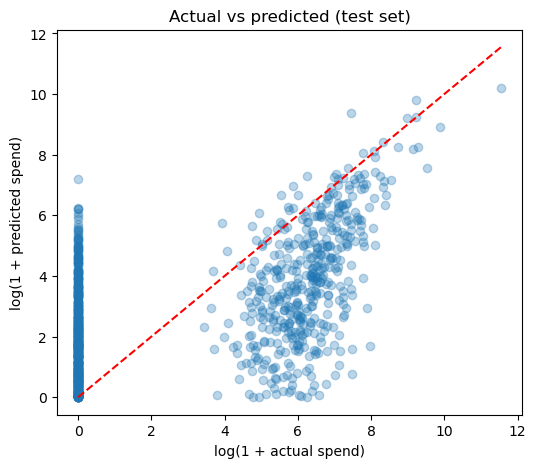

In [66]:
test_res = X_test.copy()
test_res['actual'] = y_test
test_res['pred'] = pred
test_res['abs_error'] = (test_res['actual'] - test_res['pred']).abs()

test_res['Segment'] = pd.Series(
    kmeans.predict(prep.transform(X_test)), index=X_test.index
).map(segment_names)

# 1) Error by segment
by_seg = test_res.groupby('Segment').agg(
    Customers=('actual', 'size'),
    MAE=('abs_error', 'mean'),
    Avg_actual=('actual', 'mean'),
    Avg_pred=('pred', 'mean')
).round(0)
display(by_seg)

# 2) Buyers vs non-buyers
test_res['Buyer'] = test_res['actual'] > 0
display(test_res.groupby('Buyer')['abs_error'].agg(['size', 'mean']).round(0))

# 3) Share of total error caused by the 10 largest errors
top10 = test_res.sort_values('abs_error', ascending=False).head(10)
print("Top 10 errors share of total absolute error:",
      round(top10['abs_error'].sum() / test_res['abs_error'].sum() * 100, 1), "%")
display(top10[['Recency', 'Frequency', 'Monetary', 'actual', 'pred', 'abs_error']].round(0))

# 4) Actual vs predicted (log scale)
plt.figure(figsize=(6, 5))
plt.scatter(np.log1p(test_res['actual']), np.log1p(test_res['pred']), alpha=0.3)
lim = max(np.log1p(test_res['actual']).max(), np.log1p(test_res['pred']).max())
plt.plot([0, lim], [0, lim], 'r--')
plt.xlabel('log(1 + actual spend)')
plt.ylabel('log(1 + predicted spend)')
plt.title('Actual vs predicted (test set)')
plt.show()

In [67]:
from scipy.stats import spearmanr

print("Spearman rank correlation:", round(spearmanr(test_res['actual'], test_res['pred'])[0], 3))

top20 = test_res.sort_values('pred', ascending=False).head(int(0.2 * len(test_res)))
print("Top 20% by prediction -> share of actual revenue:",
      round(top20['actual'].sum() / test_res['actual'].sum() * 100, 1), "%")
print("Top 20% by prediction -> share of all buyers:",
      round((top20['actual'] > 0).sum() / (test_res['actual'] > 0).sum() * 100, 1), "%")

Spearman rank correlation: 0.551
Top 20% by prediction -> share of actual revenue: 74.1 %
Top 20% by prediction -> share of all buyers: 37.3 %


### Test results and error analysis
On the untouched test set (1,049 customers) the tuned Random Forest reaches MAE £392, RMSE £2,535 and R² 0.44, versus MAE £509 for the strongest baseline (predict zero): a 23% reduction in average error. The result matches the cross-validation estimate (MAE 403), so there is no sign of overfitting.
- The model recognizes non-buyers well (MAE £26 for the 56% of customers who do not buy), but 96% of the total error comes from customers who do buy.
- Errors are concentrated in large customers: the VIP segment (17% of test customers) causes about 63% of the total error, the ten largest errors cause 35%, and a single customer causes 19%.
- Predictions are biased low for large customers (8 of the 10 largest errors are under-predictions; the mean predicted spend of VIPs is £1,053 versus £2,173 actual), because the model is trained on log values and returns typical rather than average spend.

# 11. Business Insights and Recommendations

1. **Protect the VIP segment first.** About 17% of customers generate about 64% of the next-90-day revenue. Loyalty rewards and early access are worth more than any other action.
2. **Win back the At Risk segment.** It is the second largest source of future revenue and almost half of its customers still buy, so reminder emails with a targeted offer are worth the cost.
3. **Do not spend on the Lost segment.** 39% of customers generate about 6% of revenue and only 20% buy again, so discounts here are wasted. Use low-cost newsletters only.
4. **Use predicted spend to rank customers inside each segment** and focus the budget on the top of the list.

### Limitations
- One cutoff date only, and the target window (Sep to Dec 2011) includes the Christmas peak, so the model may over-predict in quieter seasons.
- Customers who appear for the first time after the cutoff cannot be predicted, and sudden large wholesale orders cannot be predicted from RFM features.
- Predictions are typical values, not averages: use them to rank customers and choose actions, not to forecast total revenue.
- Segments overlap (silhouette 0.377) and "Future money pocket" is the least stable segment.
- Only transaction data is available (no demographics, product categories or marketing history).

# 12. Saving the Model for the Web App

We save the final pipeline (joblib) and a table with every customer's segment and predicted spend.
Predictions for training customers are out-of-fold (made by models that did not see that customer), and predictions for test customers come from the final model, so no prediction is made on data the model memorized.

In [68]:
import os
import joblib
import sklearn
from sklearn.model_selection import cross_val_predict

# 1) Honest predictions for every customer
oof = cross_val_predict(final_model, X_train2, y_train, cv=kf)   # training customers
all_feat = pd.concat([X_train2, X_test2])
all_y = pd.concat([y_train, y_test])
pred_all = pd.Series(np.concatenate([oof, pred]), index=all_feat.index)

# 2) Scored customer table
rfm_cols = list(X_train.columns)
scored = all_feat.copy()
scored['Segment'] = pd.Series(
    kmeans.predict(prep.transform(all_feat[rfm_cols])), index=all_feat.index
).map(segment_names)
scored['actual_next_90d'] = all_y
scored['predicted_next_90d'] = pred_all
scored['split'] = ['train'] * len(X_train2) + ['test'] * len(X_test2)

# 3) Save
os.makedirs('app', exist_ok=True)
bundle = {
    'model': final_model,
    'features': list(X_train2.columns),
    'kmeans': kmeans,
    'prep': prep,
    'rfm_features': rfm_cols,
    'segment_names': segment_names,
    'actions': actions,
}
joblib.dump(bundle, 'app/clv_model.joblib', compress=3)
scored.reset_index().to_csv('app/customers_scored.csv', index=False)

print("scikit-learn version:", sklearn.__version__)
print(scored.shape)
print(scored['Segment'].value_counts())
scored.head()

scikit-learn version: 1.6.1
(5245, 13)
Segment
Lost                   2065
At Risk                1596
VIP                     891
Future money pocket     693
Name: count, dtype: int64


,Frequency,Recency,Monetary,Tenure,UniqueProducts,AvgOrderValue,ReturnShare,Spend_last90,Orders_last90,Segment,actual_next_90d,predicted_next_90d,split
Customer ID,,,,,,,,,,,,,
16820,1,5,497.61,5,26,497.6100,0.000000,497.61,1.0,Future money pocket,0.00,78.407146,train
12380,5,95,5309.99,572,123,1069.0780,0.006623,0.00,0.0,At Risk,1861.01,77.956504,train
12782,10,59,3545.79,429,134,363.7990,0.025344,403.72,1.0,VIP,224.25,290.112549,train
16499,8,270,2491.74,456,104,322.2925,0.033588,0.00,0.0,At Risk,0.00,23.383586,train
12814,1,11,85.92,11,1,85.9200,0.000000,85.92,1.0,Future money pocket,0.00,3.806233,train


In [70]:
pip install streamlit
streamlit run app/app.py

SyntaxError: invalid syntax (1996262987.py, line 1)